In [1]:
from google.colab import files

uploaded = files.upload()

Saving dataset-ccn_project_trafficSignrecognation.zip to dataset-ccn_project_trafficSignrecognation.zip


In [2]:
import zipfile
import os

zip_path = list(uploaded.keys())[0]

extract_path = "/content/traffic_sign_dataset"

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset Extracted Successfully!")
print(os.listdir(extract_path))

Dataset Extracted Successfully!
['Test.csv', 'Meta', 'signnames.csv', 'Train', 'Test', 'Train.csv', 'Meta.csv']


In [6]:
import zipfile
import os

zip_path = list(uploaded.keys())[0]

extract_path = "/content/traffic_sign_dataset"

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset Extracted Successfully!")
print(os.listdir(extract_path))

Dataset Extracted Successfully!
['Test.csv', 'Meta', 'signnames.csv', 'Train', 'Test', 'Train.csv', 'Meta.csv']


In [42]:
import os
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

from tensorflow.keras.applications import ResNet50V2
from tensorflow.keras.applications.resnet_v2 import preprocess_input

from tensorflow.keras.layers import (
    Input,
    Dense,
    GlobalAveragePooling2D,
    Dropout,
    Lambda
)

from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import ReduceLROnPlateau

print("All Libraries Imported Successfully!")
print("TensorFlow Version:", tf.__version__)
print("GPU:", tf.config.list_physical_devices('GPU'))

All Libraries Imported Successfully!
TensorFlow Version: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [27]:
DATASET_PATH = "/content/traffic_sign_dataset"

TRAIN_CSV = os.path.join(DATASET_PATH, "Train.csv")
TEST_CSV = os.path.join(DATASET_PATH, "Test.csv")

print("Dataset Folder:", os.path.exists(DATASET_PATH))
print("Train CSV:", os.path.exists(TRAIN_CSV))
print("Test CSV:", os.path.exists(TEST_CSV))

Dataset Folder: True
Train CSV: True
Test CSV: True


In [28]:
train_df = pd.read_csv(TRAIN_CSV)
test_df = pd.read_csv(TEST_CSV)

print("Train Shape:", train_df.shape)
print("Test Shape:", test_df.shape)

print("\nTrain Columns:")
print(train_df.columns.tolist())

print("\nFirst 5 Rows:")
display(train_df.head())

Train Shape: (39209, 8)
Test Shape: (12630, 8)

Train Columns:
['Width', 'Height', 'Roi.X1', 'Roi.Y1', 'Roi.X2', 'Roi.Y2', 'ClassId', 'Path']

First 5 Rows:


,Width,Height,Roi.X1,Roi.Y1,Roi.X2,Roi.Y2,ClassId,Path
0,27,26,5,5,22,20,20,/code/Train/20/00020_00000_00000.png
1,28,27,5,6,23,22,20,/code/Train/20/00020_00000_00001.png
2,29,26,6,5,24,21,20,/code/Train/20/00020_00000_00002.png
3,28,27,5,6,23,22,20,/code/Train/20/00020_00000_00003.png
4,28,26,5,5,23,21,20,/code/Train/20/00020_00000_00004.png


In [29]:
print("Number of Training Images:", len(train_df))
print("Number of Testing Images:", len(test_df))

print("Number of Classes:", train_df['ClassId'].nunique())

print("\nClass Distribution:")
print(train_df['ClassId'].value_counts().sort_index())

print("\nMissing Values:")
print(train_df.isnull().sum())

Number of Training Images: 39209
Number of Testing Images: 12630
Number of Classes: 43

Class Distribution:
ClassId
0      210
1     2220
2     2250
3     1410
4     1980
5     1860
6      420
7     1440
8     1410
9     1470
10    2010
11    1320
12    2100
13    2160
14     780
15     630
16     420
17    1110
18    1200
19     210
20     360
21     330
22     390
23     510
24     270
25    1500
26     600
27     240
28     540
29     270
30     450
31     780
32     240
33     689
34     420
35    1200
36     390
37     210
38    2070
39     300
40     360
41     240
42     240
Name: count, dtype: int64

Missing Values:
Width      0
Height     0
Roi.X1     0
Roi.Y1     0
Roi.X2     0
Roi.Y2     0
ClassId    0
Path       0
dtype: int64


In [30]:
TRAIN_IMAGE_DIR = os.path.join(DATASET_PATH, "Train")
TEST_IMAGE_DIR = os.path.join(DATASET_PATH, "Test")

train_df['image_path'] = train_df['Path'].apply(
    lambda x: os.path.join(
        TRAIN_IMAGE_DIR,
        x.split("Train/", 1)[1]
    )
)

test_df['image_path'] = test_df['Path'].apply(
    lambda x: os.path.join(
        TEST_IMAGE_DIR,
        x.split("Test/", 1)[1]
    )
)

train_df['ClassId'] = train_df['ClassId'].astype(int)
test_df['ClassId'] = test_df['ClassId'].astype(int)

print("First Train Image:", train_df['image_path'].iloc[0])
print("First Test Image:", test_df['image_path'].iloc[0])

print("\nTrain Image Exists:",
      os.path.exists(train_df['image_path'].iloc[0]))

print("Test Image Exists:",
      os.path.exists(test_df['image_path'].iloc[0]))

First Train Image: /content/traffic_sign_dataset/Train/20/00020_00000_00000.png
First Test Image: /content/traffic_sign_dataset/Test/00000.png

Train Image Exists: True
Test Image Exists: True


In [31]:
train_missing = (~train_df['image_path'].apply(os.path.exists)).sum()
test_missing = (~test_df['image_path'].apply(os.path.exists)).sum()

print("Missing Train Images:", train_missing)
print("Missing Test Images:", test_missing)

Missing Train Images: 0
Missing Test Images: 0


In [32]:
SEED = 42

np.random.seed(SEED)
tf.random.set_seed(SEED)

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
NUM_CLASSES = 43

print("Image Size:", IMG_SIZE)
print("Batch Size:", BATCH_SIZE)
print("Number of Classes:", NUM_CLASSES)

Image Size: (224, 224)
Batch Size: 32
Number of Classes: 43


In [33]:
train_data, val_data = train_test_split(
    train_df,
    test_size=0.20,
    random_state=SEED,
    stratify=train_df['ClassId']
)

print("Training Samples:", len(train_data))
print("Validation Samples:", len(val_data))
print("Testing Samples:", len(test_df))

Training Samples: 31367
Validation Samples: 7842
Testing Samples: 12630


In [35]:
def load_image(image_path, label):

    image = tf.io.read_file(image_path)

    image = tf.io.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])

    image = tf.image.resize(image, IMG_SIZE)

    image = tf.cast(image, tf.float32)

    return image, label

In [36]:
def create_dataset(dataframe, shuffle=False):

    paths = dataframe['image_path'].values
    labels = dataframe['ClassId'].values

    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    if shuffle:
        dataset = dataset.shuffle(
            buffer_size=10000,
            seed=SEED
        )

    dataset = dataset.map(
        load_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    dataset = dataset.batch(BATCH_SIZE)

    dataset = dataset.prefetch(tf.data.AUTOTUNE)

    return dataset


train_dataset = create_dataset(train_data, shuffle=True)
val_dataset = create_dataset(val_data)
test_dataset = create_dataset(test_df)

print("Training Dataset Created!")
print("Validation Dataset Created!")
print("Testing Dataset Created!")

Training Dataset Created!
Validation Dataset Created!
Testing Dataset Created!


In [37]:
base_model = ResNet50V2(
    weights='imagenet',
    include_top=False,
    input_shape=(224, 224, 3)
)

base_model.trainable = False

print("ResNet50V2 Loaded Successfully!")
print("Base Model Trainable:", base_model.trainable)

ResNet50V2 Loaded Successfully!
Base Model Trainable: False


In [43]:
inputs = Input(shape=(224, 224, 3))

x = Lambda(preprocess_input)(inputs)

x = base_model(x, training=False)

x = GlobalAveragePooling2D()(x)

x = Dropout(0.4)(x)

outputs = Dense(
    NUM_CLASSES,
    activation='softmax'
)(x)

model = Model(inputs, outputs)

model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_7 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda_1 (Lambda)               │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50v2 (Functional)         │ (None, 7, 7, 2048)     │    23,564,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 43)             │        88,107 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,652,907 (90.23 MB)

 Trainable params: 88,107 (344.17 KB)

 Non-trainable params: 23,564,800 (89.89 MB)

In [44]:
model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("Model Compiled Successfully!")

Model Compiled Successfully!


In [45]:
lr_scheduler = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.2,
    patience=3,
    min_lr=0.00001
)

history_without_tuning = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=30,
    callbacks=[lr_scheduler]
)

Epoch 1/30
981/981 ━━━━━━━━━━━━━━━━━━━━ 169s 139ms/step - accuracy: 0.7154 - loss: 0.9449 - val_accuracy: 0.8880 - val_loss: 0.4009 - learning_rate: 0.0010
Epoch 2/30
981/981 ━━━━━━━━━━━━━━━━━━━━ 96s 98ms/step - accuracy: 0.8622 - loss: 0.4292 - val_accuracy: 0.9218 - val_loss: 0.2821 - learning_rate: 0.0010
Epoch 3/30
981/981 ━━━━━━━━━━━━━━━━━━━━ 96s 98ms/step - accuracy: 0.8904 - loss: 0.3397 - val_accuracy: 0.9322 - val_loss: 0.2386 - learning_rate: 0.0010
Epoch 4/30
981/981 ━━━━━━━━━━━━━━━━━━━━ 97s 99ms/step - accuracy: 0.8996 - loss: 0.2991 - val_accuracy: 0.9337 - val_loss: 0.2184 - learning_rate: 0.0010
Epoch 5/30
981/981 ━━━━━━━━━━━━━━━━━━━━ 97s 99ms/step - accuracy: 0.9068 - loss: 0.2770 - val_accuracy: 0.9402 - val_loss: 0.1958 - learning_rate: 0.0010
Epoch 6/30
981/981 ━━━━━━━━━━━━━━━━━━━━ 97s 99ms/step - accuracy: 0.9136 - loss: 0.2552 - val_accuracy: 0.9440 - val_loss: 0.1866 - learning_rate: 0.0010
Epoch 7/30
981/981 ━━━━━━━━━━━━━━━━━━━━ 142s 99ms/step - accuracy: 0.9177 

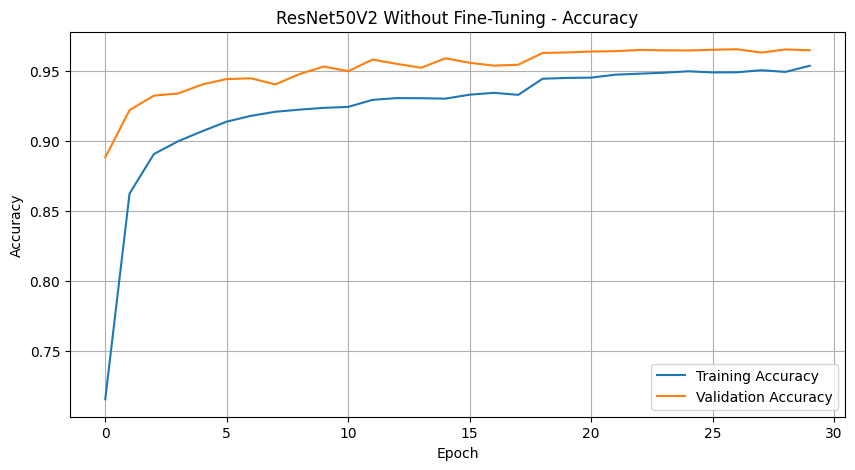

In [47]:
plt.figure(figsize=(10, 5))

plt.plot(history_without_tuning.history['accuracy'],
         label='Training Accuracy')

plt.plot(history_without_tuning.history['val_accuracy'],
         label='Validation Accuracy')

plt.title('ResNet50V2 Without Fine-Tuning - Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()

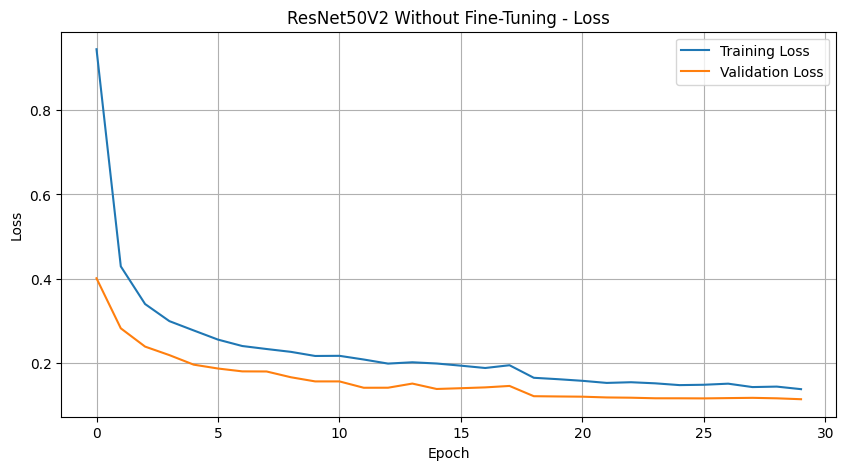

In [46]:
plt.figure(figsize=(10, 5))

plt.plot(history_without_tuning.history['loss'],
         label='Training Loss')

plt.plot(history_without_tuning.history['val_loss'],
         label='Validation Loss')

plt.title('ResNet50V2 Without Fine-Tuning - Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

In [48]:
y_true = test_df['ClassId'].values

y_prob = model.predict(test_dataset)

y_pred = np.argmax(y_prob, axis=1)

print("Prediction Completed!")
print("True Labels:", len(y_true))
print("Predicted Labels:", len(y_pred))

395/395 ━━━━━━━━━━━━━━━━━━━━ 59s 139ms/step
Prediction Completed!
True Labels: 12630
Predicted Labels: 12630


In [49]:
print(classification_report(
    y_true,
    y_pred,
    labels=np.arange(NUM_CLASSES),
    zero_division=0
))

              precision    recall  f1-score   support

           0       0.92      0.37      0.52        60
           1       0.72      0.76      0.74       720
           2       0.69      0.75      0.72       750
           3       0.66      0.52      0.58       450
           4       0.84      0.81      0.83       660
           5       0.66      0.77      0.71       630
           6       0.97      0.85      0.90       150
           7       0.92      0.84      0.88       450
           8       0.79      0.78      0.78       450
           9       0.96      0.90      0.93       480
          10       0.94      0.97      0.95       660
          11       0.90      0.88      0.89       420
          12       0.99      0.97      0.98       690
          13       0.99      1.00      0.99       720
          14       0.94      0.98      0.96       270
          15       1.00      0.99      1.00       210
          16       0.97      0.96      0.96       150
          17       1.00    

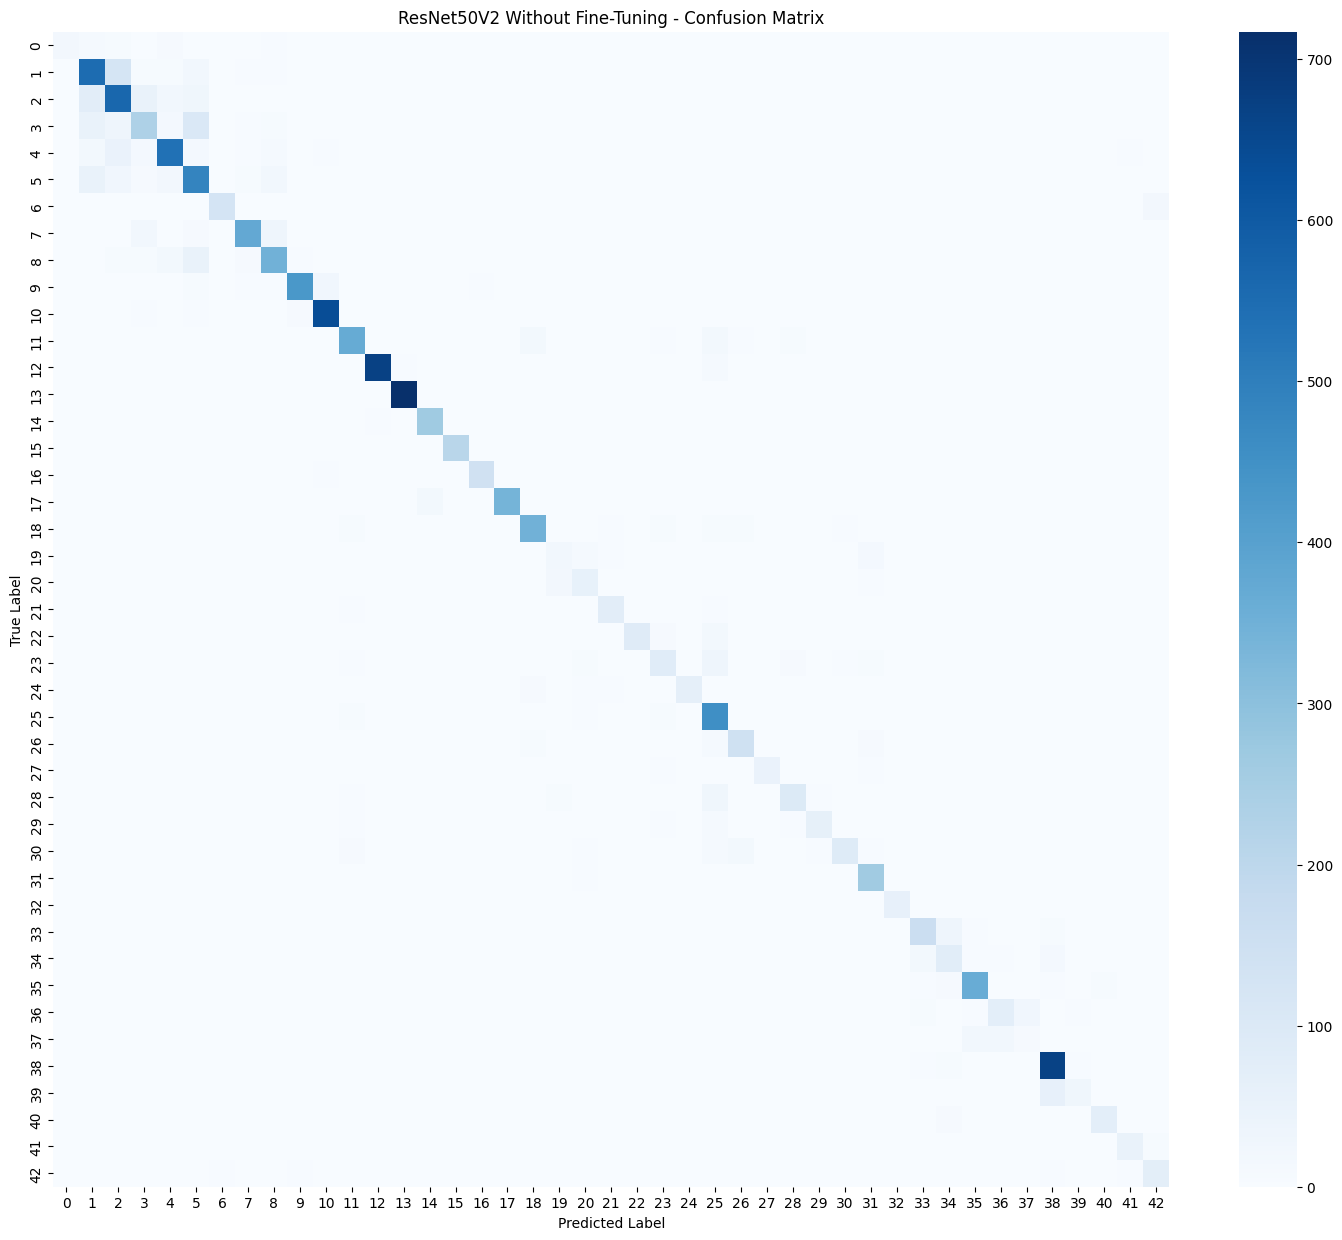

In [50]:
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=np.arange(NUM_CLASSES)
)

plt.figure(figsize=(18, 15))

sns.heatmap(
    cm,
    cmap='Blues',
    annot=False,
    fmt='d'
)

plt.title('ResNet50V2 Without Fine-Tuning - Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

In [51]:
base_model.trainable = True

for layer in base_model.layers[:-30]:
    layer.trainable = False

for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

print("Fine-Tuning Enabled!")

print("Trainable Layers:",
      sum(layer.trainable for layer in base_model.layers))

Fine-Tuning Enabled!
Trainable Layers: 22


In [52]:
model.compile(
    optimizer=Adam(learning_rate=0.00001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("Fine-Tuning Model Compiled!")

Fine-Tuning Model Compiled!


In [53]:
lr_scheduler_fine = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.2,
    patience=3,
    min_lr=0.000001
)

history_with_tuning = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=30,
    callbacks=[lr_scheduler_fine]
)

Epoch 1/30
981/981 ━━━━━━━━━━━━━━━━━━━━ 156s 145ms/step - accuracy: 0.9665 - loss: 0.0969 - val_accuracy: 0.9867 - val_loss: 0.0477 - learning_rate: 1.0000e-05
Epoch 2/30
981/981 ━━━━━━━━━━━━━━━━━━━━ 180s 131ms/step - accuracy: 0.9875 - loss: 0.0376 - val_accuracy: 0.9879 - val_loss: 0.0389 - learning_rate: 1.0000e-05
Epoch 3/30
981/981 ━━━━━━━━━━━━━━━━━━━━ 126s 129ms/step - accuracy: 0.9926 - loss: 0.0223 - val_accuracy: 0.9920 - val_loss: 0.0272 - learning_rate: 1.0000e-05
Epoch 4/30
981/981 ━━━━━━━━━━━━━━━━━━━━ 126s 129ms/step - accuracy: 0.9954 - loss: 0.0141 - val_accuracy: 0.9908 - val_loss: 0.0304 - learning_rate: 1.0000e-05
Epoch 5/30
981/981 ━━━━━━━━━━━━━━━━━━━━ 144s 131ms/step - accuracy: 0.9963 - loss: 0.0112 - val_accuracy: 0.9931 - val_loss: 0.0211 - learning_rate: 1.0000e-05
Epoch 6/30
981/981 ━━━━━━━━━━━━━━━━━━━━ 126s 129ms/step - accuracy: 0.9975 - loss: 0.0079 - val_accuracy: 0.9931 - val_loss: 0.0224 - learning_rate: 1.0000e-05
Epoch 7/30
981/981 ━━━━━━━━━━━━━━━━━━━━ 

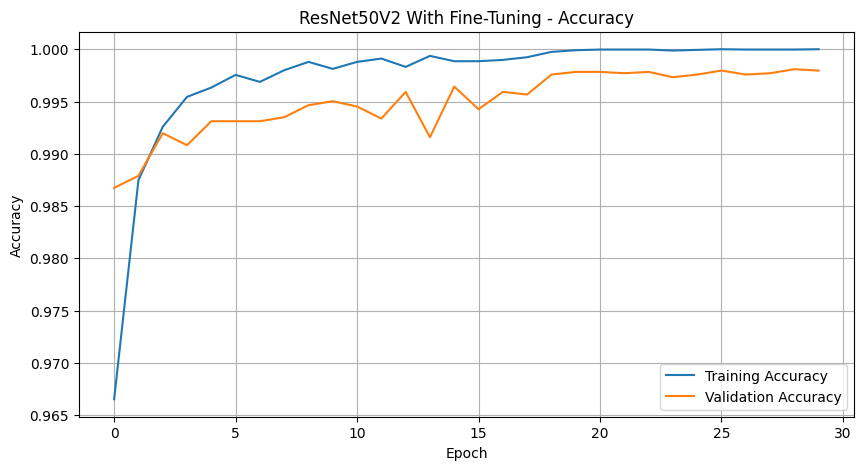

In [54]:
plt.figure(figsize=(10, 5))

plt.plot(history_with_tuning.history['accuracy'],
         label='Training Accuracy')

plt.plot(history_with_tuning.history['val_accuracy'],
         label='Validation Accuracy')

plt.title('ResNet50V2 With Fine-Tuning - Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()

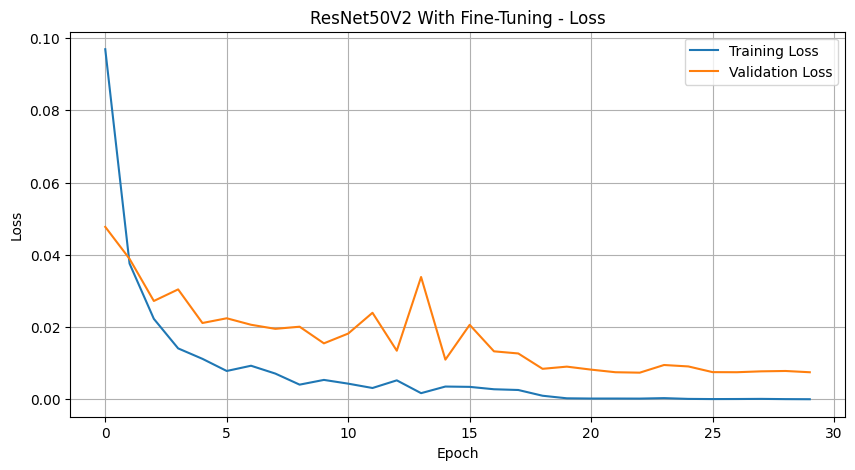

In [55]:
plt.figure(figsize=(10, 5))

plt.plot(history_with_tuning.history['loss'],
         label='Training Loss')

plt.plot(history_with_tuning.history['val_loss'],
         label='Validation Loss')

plt.title('ResNet50V2 With Fine-Tuning - Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

In [56]:
y_true = test_df['ClassId'].values

y_prob_fine = model.predict(test_dataset)

y_pred_fine = np.argmax(y_prob_fine, axis=1)

print("Fine-Tuning Prediction Completed!")
print("True Labels:", len(y_true))
print("Predicted Labels:", len(y_pred_fine))

395/395 ━━━━━━━━━━━━━━━━━━━━ 40s 90ms/step
Fine-Tuning Prediction Completed!
True Labels: 12630
Predicted Labels: 12630


In [57]:
print(classification_report(
    y_true,
    y_pred_fine,
    labels=np.arange(NUM_CLASSES),
    zero_division=0
))

              precision    recall  f1-score   support

           0       0.98      0.78      0.87        60
           1       0.95      0.96      0.95       720
           2       0.90      0.97      0.93       750
           3       0.94      0.88      0.91       450
           4       0.96      0.95      0.96       660
           5       0.89      0.93      0.91       630
           6       1.00      0.91      0.95       150
           7       0.99      0.95      0.97       450
           8       0.95      0.90      0.93       450
           9       0.99      0.97      0.98       480
          10       0.99      0.98      0.99       660
          11       0.95      0.99      0.97       420
          12       1.00      0.99      0.99       690
          13       0.99      1.00      0.99       720
          14       0.92      1.00      0.96       270
          15       1.00      1.00      1.00       210
          16       0.95      0.99      0.97       150
          17       1.00    

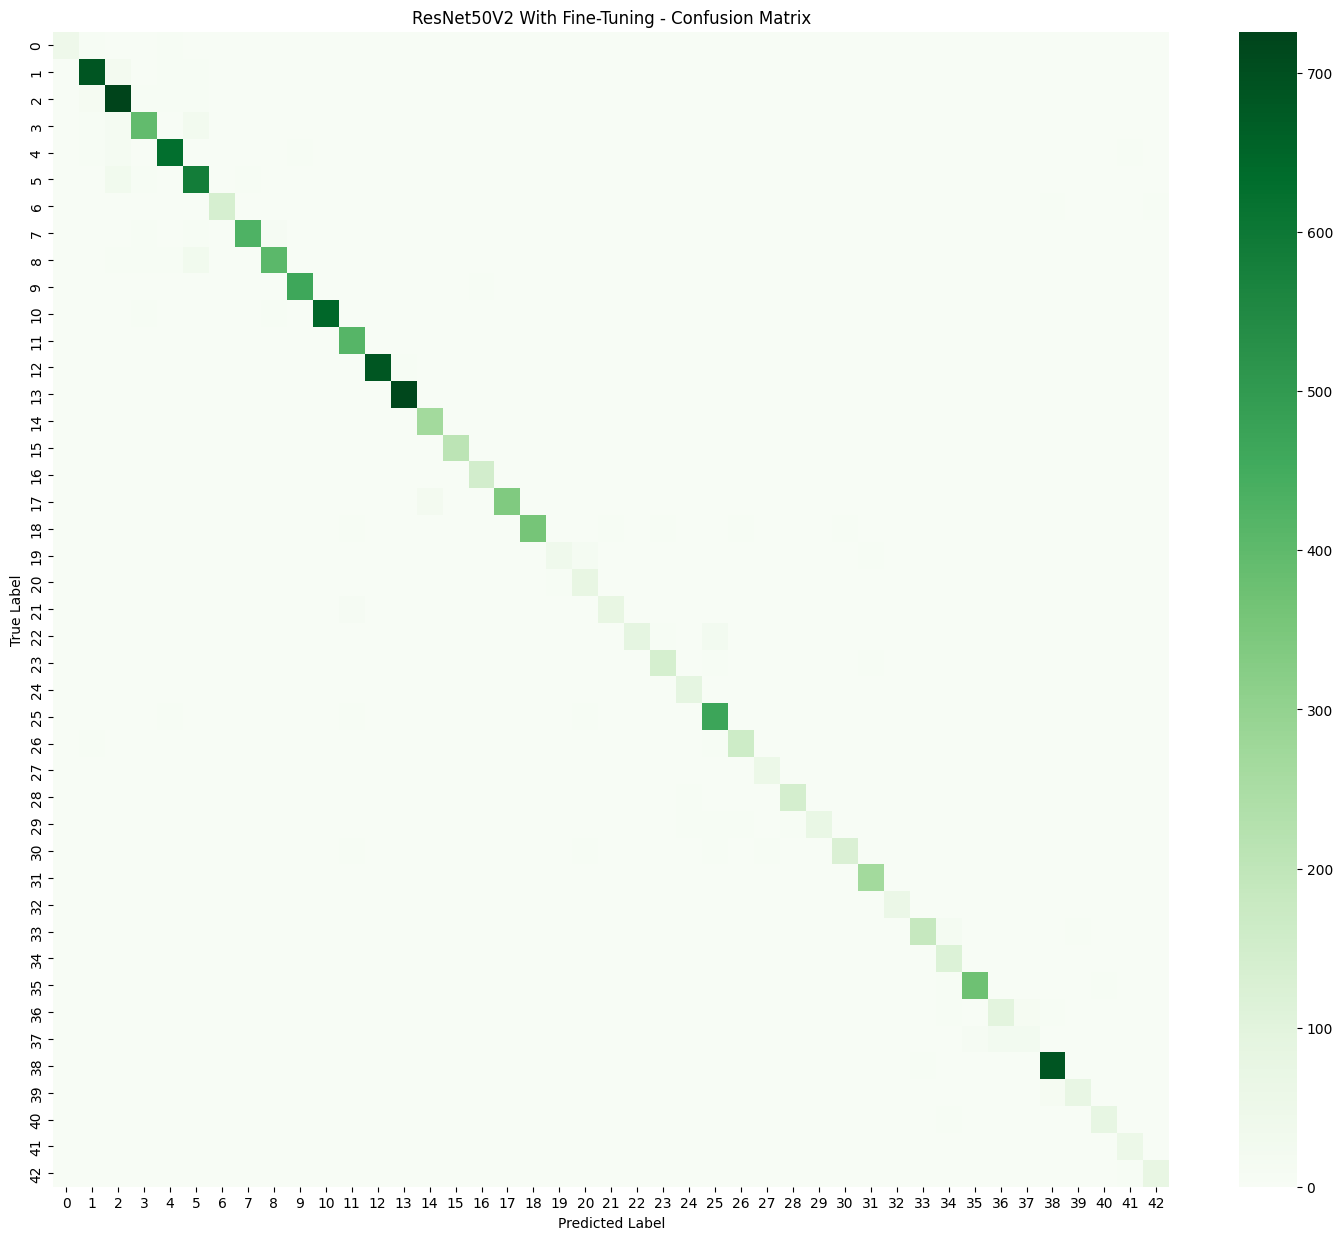

In [58]:
cm_fine = confusion_matrix(
    y_true,
    y_pred_fine,
    labels=np.arange(NUM_CLASSES)
)

plt.figure(figsize=(18, 15))

sns.heatmap(
    cm_fine,
    cmap='Greens',
    annot=False,
    fmt='d'
)

plt.title('ResNet50V2 With Fine-Tuning - Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()